## Setup

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math
from PIL import Image
from tqdm.auto import tqdm



DATA_DIR = Path("cats-and-dogs")
LABELS = ["Cat", "Dog", "Moris", "Motya", "Biatrix"]

train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")
print(train.shape, test.shape)
train.head()

(12260, 6) (18673, 1)


,image_id,Cat,Dog,Moris,Motya,Biatrix
0,7e17a6e589f9c891857b32bbb3652d19b7d5a215,0,0,0,0,0
1,7ad97bd6c7ef98373f43f2bbd1e41b2bbff4687e,1,0,0,0,0
2,d29be872d012d8766c5942847d1d721788fd9511,0,1,0,0,0
3,bec7727bfc721629997d782ec020ee555990128f,0,1,0,0,0
4,58bb7362153d945f48721004bc8fb2ee73a855b0,0,1,0,0,0


### Classes

In [3]:
# Label checks: frequency, hierarchy violations, combinations
print("duplicate ids:", train.image_id.duplicated().sum())

freq = train[LABELS].agg(["sum", "mean"]).T
print(freq)

for lable1 in LABELS:
    for lable2 in LABELS:
        n = ((train[lable1] == 1) & (train[lable2] == 0)).sum()
        print(f"{lable1} and not {lable2}:", n)

duplicate ids: 0
            sum      mean
Cat      5077.0  0.414111
Dog      5025.0  0.409869
Moris      56.0  0.004568
Motya      42.0  0.003426
Biatrix    41.0  0.003344
Cat and not Cat: 0
Cat and not Dog: 5073
Cat and not Moris: 5021
Cat and not Motya: 5035
Cat and not Biatrix: 5073
Dog and not Cat: 5021
Dog and not Dog: 0
Dog and not Moris: 5021
Dog and not Motya: 5025
Dog and not Biatrix: 4984
Moris and not Cat: 0
Moris and not Dog: 52
Moris and not Moris: 0
Moris and not Motya: 46
Moris and not Biatrix: 52
Motya and not Cat: 0
Motya and not Dog: 42
Motya and not Moris: 32
Motya and not Motya: 0
Motya and not Biatrix: 42
Biatrix and not Cat: 37
Biatrix and not Dog: 0
Biatrix and not Moris: 37
Biatrix and not Motya: 41
Biatrix and not Biatrix: 0


In [ ]:
def image_meta(split, ids):
    rows = []
    for image_id in tqdm(ids):
        path = DATA_DIR / split / f"{image_id}.jpg"
        try:
            with Image.open(path) as im:
                im.verify()
            with Image.open(path) as im:
                rows.append((image_id, im.width, im.height, im.mode, path.stat().st_size, True))
        except Exception:
            rows.append((image_id, None, None, None, None, False))
    return pd.DataFrame(rows, columns=["image_id", "w", "h", "mode", "bytes", "ok"])


meta_train = image_meta("train", train.image_id)
meta_test = image_meta("test", test.image_id)
print("corrupt:", (~meta_train.ok).sum(), (~meta_test.ok).sum())
print(meta_train["mode"].value_counts(), meta_test["mode"].value_counts())
meta_train[["w", "h"]].describe()

100%|██████████| 18673/18673 [00:08<00:00, 2290.13it/s]


corrupt: 0 0
mode
RGB    12260
Name: count, dtype: int64 mode
RGB    18673
Name: count, dtype: int64


,w,h
count,18673.0,18673.0
mean,450.0,375.0
std,0.0,0.0
min,450.0,375.0
25%,450.0,375.0
50%,450.0,375.0
75%,450.0,375.0
max,450.0,375.0


### Preview

In [ ]:
def show_grid(mask, n=12, cols=4):
    sample = train[mask].sample(min(n, mask.sum()), random_state=67)
    rows = math.ceil(len(sample) / cols)

    fig, axes = plt.subplots(rows, cols, figsize=(cols * 3, rows * 3))
    axes = axes.ravel()

    for ax in axes:
        ax.axis("off")

    for ax, (_, row) in zip(axes, sample.iterrows()):
        img = Image.open(DATA_DIR / "train" / f"{row.image_id}.jpg")
        ax.imshow(img)

    plt.show()

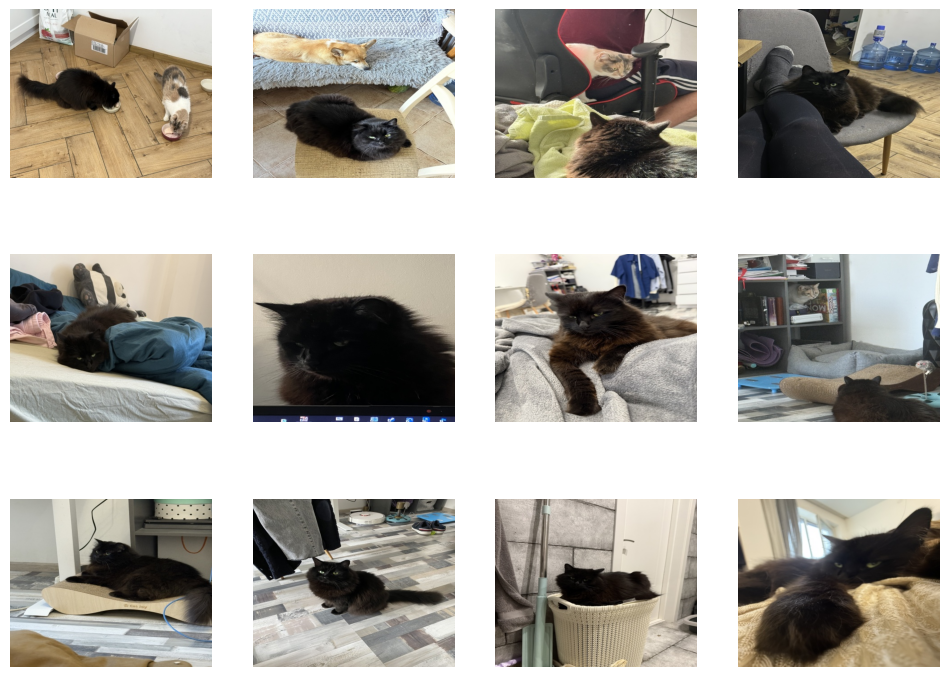

In [10]:
show_grid(train.Moris == 1)

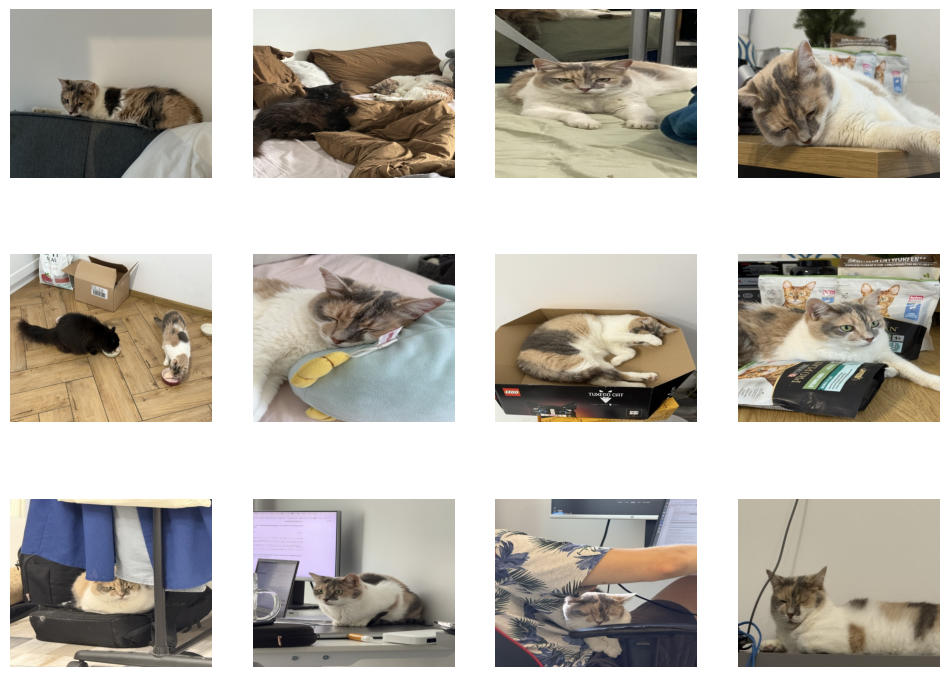

In [11]:
show_grid(train.Motya == 1)

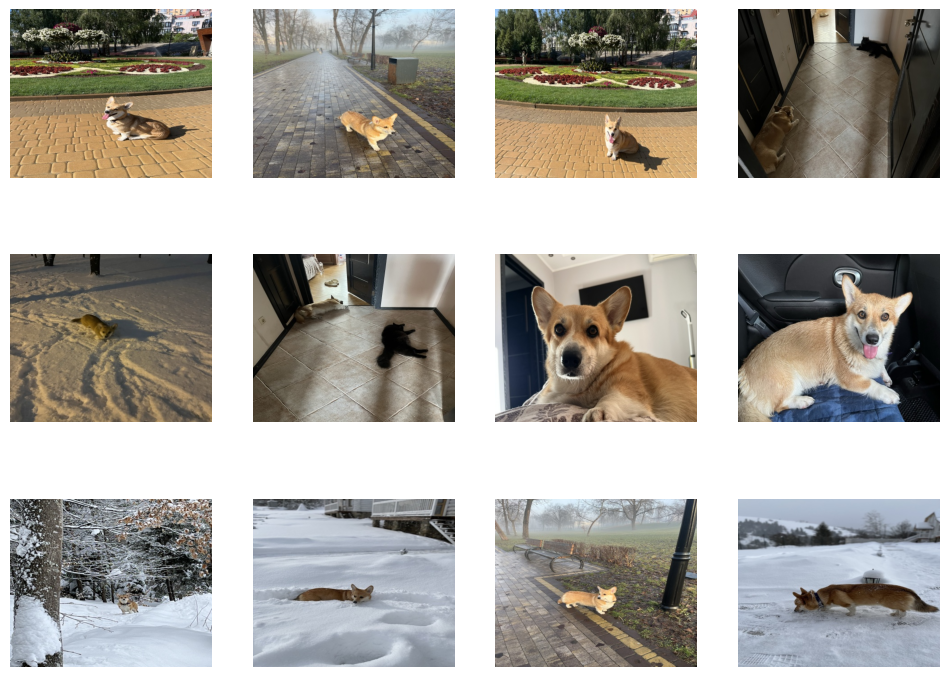

In [14]:
show_grid(train.Biatrix == 1)

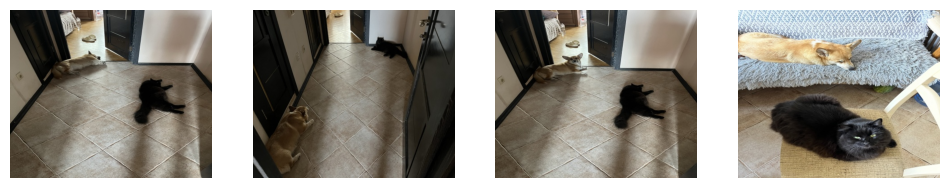

In [19]:
show_grid(((train.Biatrix == 1)&(train.Moris == 1)))

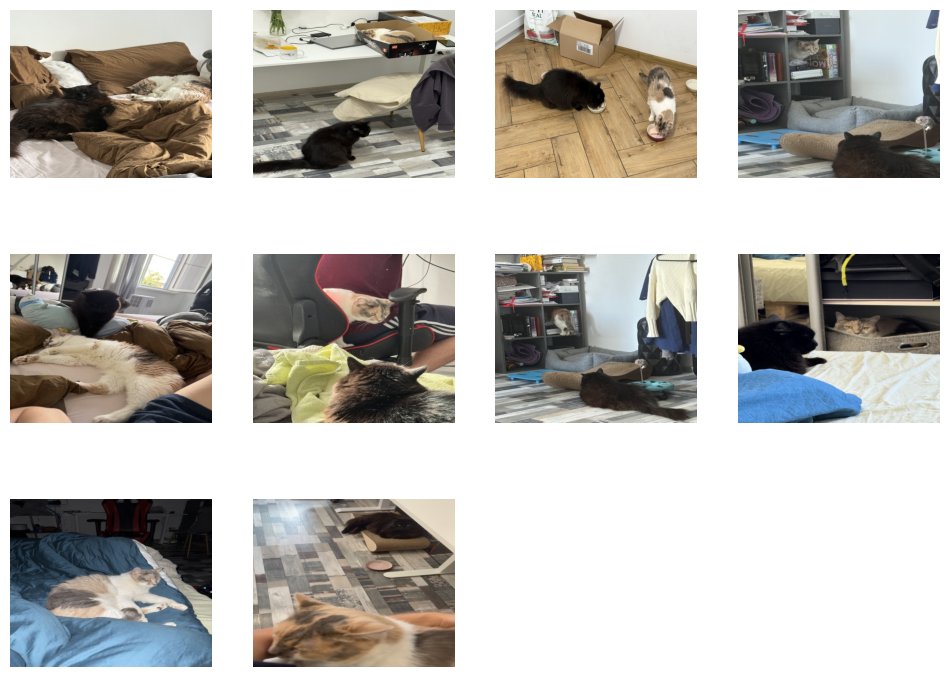

In [20]:
show_grid(((train.Motya == 1)&(train.Moris == 1)))

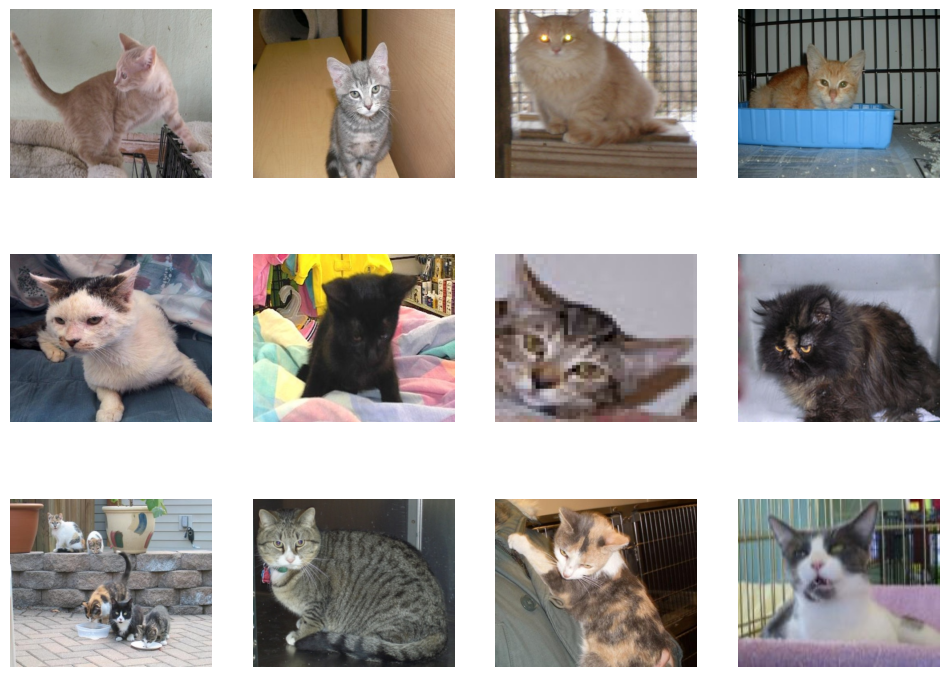

In [25]:
show_grid(train.Cat==1)

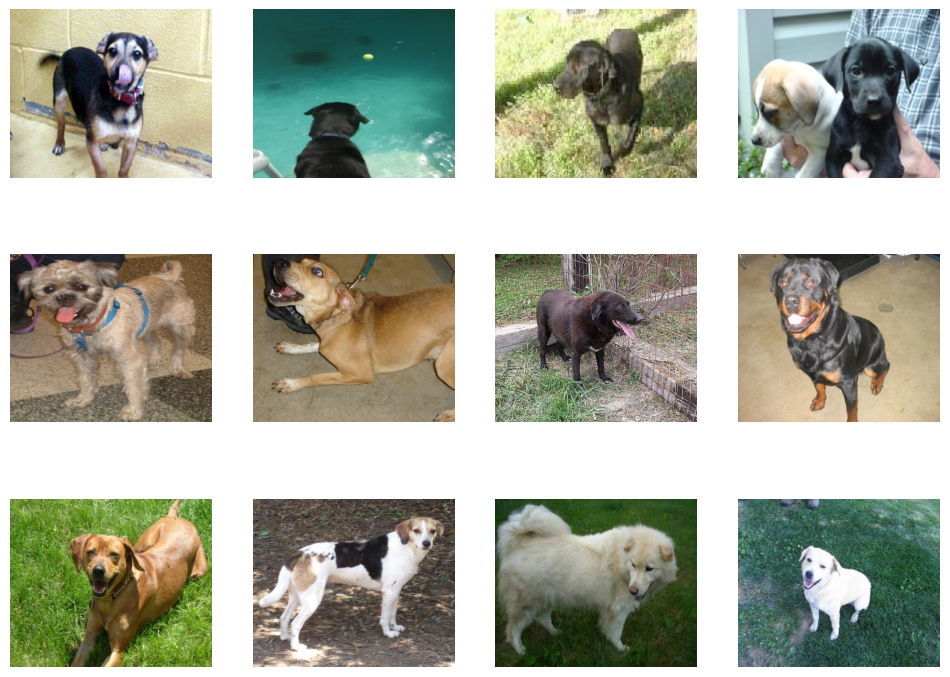

In [26]:
show_grid(train.Dog==1)

### Simple adversarial validation

In [9]:
def sharpness(gray):
    center = gray[1:-1, 1:-1]
    up     = gray[:-2, 1:-1]
    down   = gray[2:, 1:-1]
    left   = gray[1:-1, :-2]
    right  = gray[1:-1, 2:]
    return (up + down + left + right - 4*center).var()


def image_features(split, ids):
    rows = []
    for image_id in tqdm(ids):
        path = DATA_DIR / split / f"{image_id}.jpg"
        with Image.open(path) as im:
            rgb = np.asarray(im.convert("RGB"), dtype=np.float32)
        gray = rgb.mean(axis=2)
        r, g, b = rgb.reshape(-1, 3).mean(axis=0)
        rows.append((image_id, gray.mean(), gray.std(), r, g, b, sharpness(gray), path.stat().st_size))
    return pd.DataFrame(
        rows, columns=["image_id", "brightness", "contrast", "r", "g", "b", "sharpness", "bytes"]
    )


feat_train = image_features("train", train.image_id)
feat_test = image_features("test", test.image_id)
feat_train.describe()

100%|██████████| 18673/18673 [07:01<00:00, 44.26it/s]


,brightness,contrast,r,g,b,sharpness,bytes
count,12260.000000,12260.000000,12260.000000,12260.000000,12260.000000,12260.000000,12260.000000
mean,116.860886,55.063316,125.058769,118.144920,107.395309,465.443237,58353.039152
std,30.720978,13.752203,33.274479,31.412123,33.736835,699.036682,16464.649797
min,7.453207,10.487996,6.852848,7.370234,6.657677,5.489273,7690.000000
25%,97.369429,45.509478,103.926434,98.218330,85.334461,123.105576,47056.250000
50%,115.259377,54.486664,124.440228,117.024757,105.266918,247.669113,55818.500000
75%,134.066319,64.049412,144.491894,136.128216,126.427856,525.798813,67096.500000
max,250.946320,123.485626,254.420914,251.577225,251.080444,13613.174805,148500.000000


In [11]:
! pip install scikit-learn

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.4/62.4 kB 920.9 kB/s eta 0:00:00 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.2/9.2 MB 21.9 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 306.1/306.1 kB 26.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 483.2/483.2 kB 27.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 29.0 MB/s eta 0:00:0000:0100:01


In [15]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split

FEATS = ["brightness", "contrast", "r", "g", "b", "sharpness", "bytes"]

X = pd.concat([feat_train[FEATS], feat_test[FEATS]], ignore_index=True)
y = np.concatenate([np.zeros(len(feat_train)), np.ones(len(feat_test))])

X_tr, X_va, y_tr, y_va = train_test_split(X, y, test_size=0.25, stratify=y, random_state=67)
clf = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.1, random_state=0)
clf.fit(X_tr, y_tr)
print("adversarial AUC:", roc_auc_score(y_va, clf.predict_proba(X_va)[:, 1]))

adversarial AUC: 0.5006281408351989
